# Week 1 EDA: the sampled application table

Work through the sections in order. Cells marked **PROVIDED** run as they are. For each
**TODO(student)** section, answer the question with code in the empty cell, then write one
or two sentences of what you see. Keep reusable code in `src/`; this notebook is for looking.

Run it from the repository root with `jupyter notebook` (or `jupyter lab`) after `python run.py sample`.

## 1. Load the sample  (PROVIDED)

In [1]:
# PROVIDED
import sys
from pathlib import Path

import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data import load_application  # noqa: E402
from src.utils import load_config  # noqa: E402

config = load_config(ROOT / "config" / "config.yaml")
app = load_application(config)
print(app.shape)
app.head()

Matplotlib is building the font cache; this may take a moment.


(5000, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100021,0,Revolving loans,F,N,Y,1,81000.0,270000.0,13500.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,100030,0,Cash loans,F,N,Y,0,90000.0,225000.0,11074.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100033,0,Cash loans,M,Y,Y,0,270000.0,790830.0,57676.5,...,0,0,0,0,0.0,0.0,0.0,1.0,0.0,1.0
3,100294,0,Cash loans,F,N,Y,0,157500.0,835380.0,35392.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
4,100322,0,Cash loans,M,Y,Y,2,225000.0,254700.0,26874.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Target rate  (PROVIDED)

TARGET
0    4596
1     404
Name: count, dtype: int64
Default rate: 8.08%


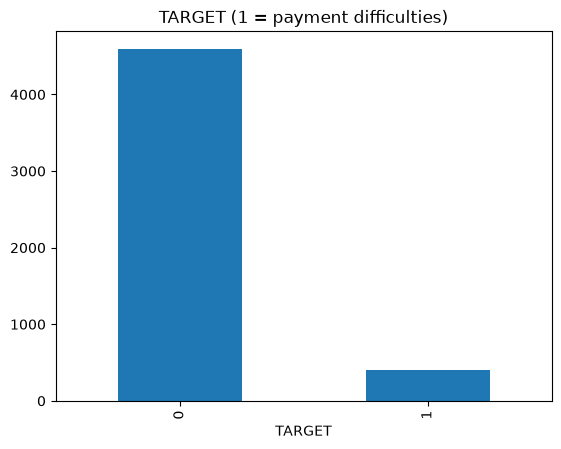

In [7]:
# PROVIDED
counts = app["TARGET"].value_counts().sort_index()
print(counts)
print(f"Default rate: {app['TARGET'].mean():.2%}")
counts.plot.bar(title="TARGET (1 = payment difficulties)")
plt.show()

## 3. Missingness  (TODO(student))

Which columns have the most missing values? How many columns are more than half empty?
Do the most-missing columns seem to belong together (look at their names)?

In [8]:
missing = app.isna().mean().sort_values(ascending=False)
print(missing.head(20).map("{:.1%}".format))

over_half = missing[missing > 0.5]
print(f"\nColumns more than half empty: {len(over_half)} of {app.shape[1]}")

print(over_half.index.str.extract(r"_(AVG|MODE|MEDI)$")[0].value_counts(dropna=False))

COMMONAREA_MODE             71.4%
COMMONAREA_AVG              71.4%
COMMONAREA_MEDI             71.4%
NONLIVINGAPARTMENTS_MODE    71.0%
NONLIVINGAPARTMENTS_AVG     71.0%
NONLIVINGAPARTMENTS_MEDI    71.0%
LIVINGAPARTMENTS_AVG        70.2%
LIVINGAPARTMENTS_MODE       70.2%
LIVINGAPARTMENTS_MEDI       70.2%
FONDKAPREMONT_MODE          70.1%
FLOORSMIN_MEDI              69.6%
FLOORSMIN_MODE              69.6%
FLOORSMIN_AVG               69.6%
YEARS_BUILD_MEDI            68.1%
YEARS_BUILD_AVG             68.1%
YEARS_BUILD_MODE            68.1%
OWN_CAR_AGE                 65.9%
LANDAREA_MEDI               61.0%
LANDAREA_MODE               61.0%
LANDAREA_AVG                61.0%
dtype: str

Columns more than half empty: 48 of 122
0
MODE    18
AVG     14
MEDI    14
NaN      2
Name: count, dtype: int64


# TODO(student)
48 of the 122 columns are half empty, most notably (COMMONAREA, NONLIVINGAPARTMENTS, LIVINGAPARTMENTS) are about 70% empty. 46 of those 48 are building statistics recorded in _AVG/_MODE/_MEDI triplets with identical missing rates, which suggests they go missing together, likely because the applicant’s housing information was not recorded at all.

## 4. The DAYS_EMPLOYED anomaly  (TODO(student))

Look at the distribution of `DAYS_EMPLOYED`. Which value looks impossible, and how many
applicants have it? Is the default rate of those applicants different from everyone else's?
What does that tell you about how to handle it?

count      5000.000000
mean      63622.116200
std      141057.282676
min      -15202.000000
25%       -2686.750000
50%       -1198.000000
75%        -305.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

Positive values:
DAYS_EMPLOYED
365243    897
Name: count, dtype: int64
Applicants with the anomaly: 897 (17.9%)
               default_rate  applicants
DAYS_EMPLOYED                          
normal             0.087741        4103
anomalous          0.049052         897


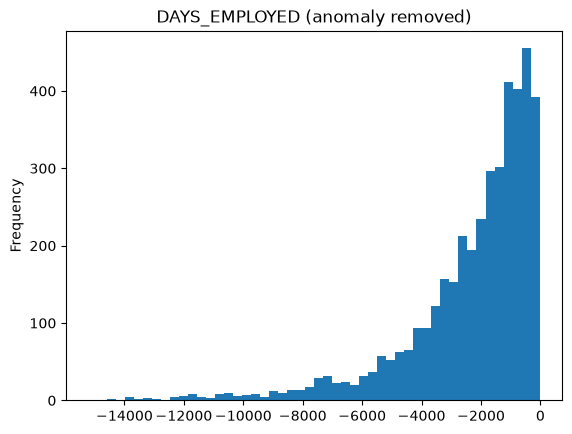

In [9]:
days = app["DAYS_EMPLOYED"]
print(days.describe())

# DAYS_* columns should be negative, so any positive value is impossible
anomalous = days > 0
print("\nPositive values:")
print(days[anomalous].value_counts())
print(f"Applicants with the anomaly: {anomalous.sum()} ({anomalous.mean():.1%})")

# Default rate: anomalous vs everyone else
rates = app.groupby(anomalous)["TARGET"].agg(default_rate="mean", applicants="count")
rates.index = rates.index.map({False: "normal", True: "anomalous"})
print(rates)

days[~anomalous].plot.hist(bins=50, title="DAYS_EMPLOYED (anomaly removed)")
plt.show()

# TODO(student)
DAYS_EMPLOYED has the 'impossible value' 365243, stored by 897 applicants (17.9%). These applicants default at 4.9% versus 8.8% for everyone else, not random noise. In clean_application it should be replaced with a missing value and kept as a flag column, so the model loses the impossible number but keeps the lower-risk signal.

## 5. Default rate by a categorical column  (TODO(student))

Pick one categorical column (for example `NAME_CONTRACT_TYPE`, `CODE_GENDER`, or
`OCCUPATION_TYPE`). Show the default rate and the number of applicants in each category.
Which differences would you trust, given how few applicants some categories have?

In [ ]:
col = "CODE_GENDER"

summary = (
    app.groupby(col, dropna=False)["TARGET"]
    .agg(default_rate="mean", applicants="count")
    .sort_values("applicants", ascending=False)
)
summary["defaulters"] = (summary["default_rate"] * summary["applicants"]).round().astype(int)
summary["default_rate"] = summary["default_rate"].map("{:.2%}".format)
print(f"Overall default rate: {app['TARGET'].mean():.2%}\n")
summary

Overall default rate: 8.08%



,default_rate,applicants,defaulters
CODE_GENDER,,,
F,6.80%,3322,226
M,10.61%,1678,178


# TODO(student)
Men default at 10.61% (178 of 1,678) versus 6.80% for women (226 of 3,322), against an overall rate of 8.08%. Both groups are large, so this difference is trustworthy rather than noise.

## 6. Correlations with TARGET  (TODO(student))

Which numeric columns are most correlated with `TARGET` (positively and negatively)?
Remember the sign conventions: `DAYS_*` columns are negative numbers of days before the
application. Is a correlation of 0.1 large or small here?

In [ ]:
num = app.select_dtypes("number").drop(columns=["SK_ID_CURR", "TARGET"])

# Mask the 365243 placeholder from Section 4 so it doesn't distort the result
num["DAYS_EMPLOYED"] = num["DAYS_EMPLOYED"].where(app["DAYS_EMPLOYED"] <= 0)

corr = num.corrwith(app["TARGET"]).dropna().sort_values()

print("Most negative (higher value -> fewer defaults):")
print(corr.head(8).round(3))
print("\nMost positive (higher value -> more defaults):")
print(corr.tail(8).round(3))

# TODO(student)
The three external credit scores (EXT_SOURCE_1–3, about −0.16 to −0.19) are by far the strongest signals: higher scores mean fewer defaults. Following, DAYS_EMPLOYED (+0.096) and DAYS_BIRTH (+0.083), which, because DAYS_* are negative, mean shorter employment and younger age go with more defaults. Every other column is below 0.07, so with an 8% default rate a correlation near 0.1 is relatively strong, and no single column predicts default well on its own.

## 7. Findings  (TODO(student))

Write 4 to 6 bullet points: what you learned and what it means for the baseline model.

- TODO(student)

- 48 of 122 columns are more than half empty, and 46 of them are building statistics in _AVG/_MODE/_MEDI triplets that go missing together.
    - These columns must be filled before the model can use them.
- Defaults are rare: 8.08%
    - A model that predicts “no default” for everyone scores 91.9% accuracy while catching zero defaulters, meaning accuracy should not be a metric worth pursing.
- Only a few columns carry real signal: EXT_SOURCE_1–3 (about −0.16 to −0.19), then DAYS_EMPLOYED (+0.096) and DAYS_BIRTH (+0.083); everything else is below 0.07
    - The external scores, tenure, and age should be the core features. Santity Test could look like checking that the model ranks them high.
- Men default at 10.61% versus 6.80% for women, and with groups of 1,678 and 3,322 that gap is real.
    - Gender is still a protected attribute in lending. Exclusion of gender might be necessary or consistiantly check for fairness.